<span style="font-size:2em;">Instructor: Dr. Qipei (Gavin) Mei (qipei.mei@ualberta.ca)</span>

<span style="font-size:2em;">Student Name: Amilcar Díaz</span>

<span style="font-size:2em;">CCID: adiazgar</span>

# Practical Implementation of Machine learning Models [15 Marks]

1.1 Please explain how you can identify a High Bias (Low Variance) model? [2 Marks]

In [ ]:
# TODO: Please provide your answers here. You can add more cells for code or texts if needed. 
# Don't delete these two comments so that it would be easier for me to locate your answers.

A high bias (low variance) model can be identified by comparing the model's error, measured with the cost function, on the training set and on the validation set. If the training and validation errors are similar, the model has low variance. If, in addition, both errors are high, or not acceptable for the problem being analyzed, the model also has high bias, which means it underfits the data.

1.2 Give an example of a High Variance model. How do you fix the issue if the number of training samples stays the same? [2 Marks]

In [ ]:
# TODO: Please provide your answers here. You can add more cells for code or texts if needed. 
# Don't delete these two comments so that it would be easier for me to locate your answers.

A high variance model is one that does not perform the same way on the training data as on the validation data.

If the error on the validation data is higher than on the training data, we are facing an overfitting problem. It can be fixed by reducing the complexity of the model (lowering the degree of the polynomial or the number of features considered) or by tuning hyperparameters such as the regularization parameter λ (increasing it), so that the model is less flexible.

On the other hand, the case where the validation error is lower than the training error is unlikely. It would suggest that something went wrong when building the model, and the low validation error may simply be due to chance. In this scenario, I would rebuild the model from the beginning, making sure that the training data is a representative sample.

1.3 Why do we usually split the dataset into three instead of two? [2 Marks]

In [ ]:
# TODO: Please provide your answers here. You can add more cells for code or texts if needed. 
# Don't delete these two comments so that it would be easier for me to locate your answers.

Because building a model requires two decisions: choosing the parameters θ and choosing the hyperparameters of the model. At the start, we may have a number of candidate models, one for each combination of hyperparameters considered for the problem. If we split the dataset into three parts (training, validation and test):

- The **training** set is used to find the parameters θ of each candidate model (each combination of hyperparameters).
- The **validation** set is used to evaluate the performance of each of those models and select the best one (the best combination of hyperparameters).
- Finally, the **test** set is used to confirm that the selected model performs equally well on completely new data that it did not see while it was being built.

1.4 List at least 3 different types of Cross-Validation techniques? What are their pros and cons. [2 Marks]

In [ ]:
# TODO: Please provide your answers here. You can add more cells for code or texts if needed. 
# Don't delete these two comments so that it would be easier for me to locate your answers.

**1. Hold-out cross-validation**

The dataset is split into three parts, usually in a 60/20/20 proportion. The first part, the **training set**, is used to train models with different combinations of hyperparameters. The second part, the **validation set**, is used to evaluate the performance of each of those models and select the one that performs best. In this way, we can choose the number of features, the complexity of the model and the regularization parameter λ that controls how closely the model fits the data. Finally, the third part, the **test set**, is used to evaluate the final model on data that is completely new to it and that did not influence any of the decisions made while building it.

- *Pros:* the final model is tested on fully independent data, the computational cost is low, and it works well for medium and large datasets.
- *Cons:* for small datasets it loses accuracy and reliability, because the validation and test sets may not cover all the possible scenarios of the problem being analyzed.

**2. K-fold cross-validation**

The dataset is split into k parts (folds), and each candidate model (each combination of hyperparameters) is trained and validated k times, each time training on k − 1 folds and using the remaining fold for validation. Each candidate model therefore has k training runs and k validation results; their performance is averaged, and the model with the best overall performance is selected. Finally, the selected model is retrained on the whole training dataset and evaluated on the test set for a final check.

- *Pros:* it covers different scenarios that could be missed by the hold-out method, where the dataset is split only once at random.
- *Cons:* depending on the number of candidate models, the size of the dataset and the value of k, the computational cost can be high.

**3. Leave-one-out cross-validation (LOOCV)**

It is similar to k-fold but more extreme: only one data point is left out for validation, and the remaining n − 1 data points are used to train the models. The process is repeated as many times as there are data points (k = n), and the performance of each candidate model is averaged to select the one with the best average.

- *Pros:* it is a good solution for small datasets, where the previous techniques cannot be applied effectively.
- *Cons:* for large datasets, its computational cost is very high.

1.5 Why can regularization help overcome the overfitting issue in machine learning? [2 Marks]

In [ ]:
# TODO: Please provide your answers here. You can add more cells for code or texts if needed. 
# Don't delete these two comments so that it would be easier for me to locate your answers.

The regularization term in the cost function helps overcome overfitting because it controls the size of the parameters θ through the factor λ. When the θ values are large, the model tends to be more flexible and fits the training data too closely, which can lead to overfitting. In contrast, with small θ values the model becomes more rigid (smoother), and its response averages out the training data instead of following every point.

However, λ must be chosen carefully: if λ is too large, the θ values (except θ₀) tend to zero and the model approaches a horizontal line at the average of the training data, which leads to underfitting. The key is to tune λ so that the model fits the training data well while the cost function on the validation and/or test data remains similar to the cost function on the training data.

1.6 Assume that the house price is related to two factors, i.e. house size and number of bedrooms. We can use a multi-variate linear regression model to fit the data. The model is y=$\theta$<sub>0</sub>+$\theta$<sub>1</sub>x<sub>1</sub>+$\theta$<sub>2</sub>x<sub>2</sub> where y is the predicted house price, x<sub>1</sub> is the house size and x<sub>2</sub> is the number of bedrooms. Below are 15 data points for training and validation (different than the data given in Q1 of assignment 2). 

House Size (sqft), x<sub>1</sub>|Number of Bedrooms, x<sub>2</sub> | House Price (CAD), y
-----|-----|----- 
2132|3|460229
2258|3|516232
1642|2|386751
1332|2|307990
1743|3|415409
2456|3|600718
2688|4|648116
2842|4|672542
3012|5|771245
1437|2|320089
1285|2|294514
1129|1|241874
2524|3|600702
3313|5|782041
3523|5|873183

You are asked to implement 5-fold cross validation (repeat this 5 times: use 4 folds for training a linear regression model, and use the remaining fold for validation. Choose different folds for validation every time) either by yourself or using the KFold function in scikit-learn package. For each of the 5 rounds, you should report the R2 value of the model on the validation fold (you can directly use score function of the linear regression model to output this). Also, report the average of all 5 R2 values. **Note: For marking purpose, please do not shuffle the data before you implement the 5-fold cross validation.** [5 Marks]

In [47]:
# TODO: Please provide your answers here. You can add more cells for code or texts if needed. 
# Don't delete these two comments so that it would be easier for me to locate your answers.

In [15]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold

# Features
x1 = np.array([2132, 2258, 1642, 1332, 1743, 2456, 2688, 2842,
               3012, 1437, 1285, 1129, 2524, 3313, 3523])
x2 = np.array([3, 3, 2, 2, 3, 3, 4, 4, 5, 2, 2, 1, 3, 5, 5])
X = np.column_stack((x1, x2))

# Price
y = np.array([460229, 516232, 386751, 307990, 415409, 600718, 648116,
              672542, 771245, 320089, 294514, 241874, 600702, 782041, 873183])


kf = KFold(n_splits=5, shuffle=False)
r2_scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X), start=1):
    model = LinearRegression()
    model.fit(X[train_idx], y[train_idx])
    r2 = model.score(X[val_idx], y[val_idx])
    r2_scores.append(r2)
    print(f"Fold {fold}: validation rows = {val_idx + 1}")
    print(f"   theta0 = {model.intercept_:.2f}\n   theta1 = {model.coef_[0]:.2f}\n   "
          f"theta2 = {model.coef_[1]:.2f}\n   R2 = {r2:.4f}")
    
print(f"\nAverage R2 over the 5 folds = {np.mean(r2_scores):.4f}")

Fold 1: validation rows = [1 2 3]
   theta0 = -36467.22
   theta1 = 232.35
   theta2 = 16064.69
   R2 = 0.6805
Fold 2: validation rows = [4 5 6]
   theta0 = -40174.58
   theta1 = 221.65
   theta2 = 22849.03
   R2 = 0.9809
Fold 3: validation rows = [7 8 9]
   theta0 = -37785.31
   theta1 = 253.35
   theta2 = -689.19
   R2 = 0.7006
Fold 4: validation rows = [10 11 12]
   theta0 = -41160.47
   theta1 = 230.63
   theta2 = 17464.27
   R2 = 0.9773
Fold 5: validation rows = [13 14 15]
   theta0 = -40556.80
   theta1 = 221.74
   theta2 = 23834.59
   R2 = 0.9674

Average R2 over the 5 folds = 0.8614


# Support Vector Machine [15 Marks]
Build a support vector machine model for the following classification problem. The input features are x<sub>1</sub> and x<sub>2</sub>, and output is y where 0 and 1 represent two different categories. The data below is the same as Q2 of assignment 2.

x<sub>1</sub>|x<sub>2</sub> |y
-----|-----|----- 
1.35|0.311|0
2.019|0.687|1
1.659|1.247|1
1.566|0.323|0
1.74|0.765|1
1.603|0.924|1
2.194|-0.401|0
1.202|1.581|1
1.93|1.052|1
1.196|1.544|1
2.021|-0.157|0
1.32|0.272|0
1.823|1.062|1
1.169|0.734|0
1.226|1.771|1
1.107|0.78|0
2.031|-0.354|0
1.487|1.272|1
1.921|0.011|0
1.932|0.994|1
1.59|-0.056|0
1.758|0.142|0

Answer the following questions (**Please note you will not get credit if you do not use the methods as specified**):

2.1 What is the difference between Hard Margin SVM and Soft Margin SVM? [3 Marks]

In [ ]:
# TODO: Please provide your answers here. You can add more cells for code or texts if needed. 
# Don't delete these two comments so that it would be easier for me to locate your answers.

The difference is that a **hard margin SVM** does not allow any sample of the dataset to lie inside the margin, even when the dataset contains samples with distortion or noise. Moreover, if a sample lies within the group of the other class (i.e., it cannot be correctly classified by a straight line, so the data is not linearly separable), the hard margin SVM has no solution.

In contrast, a **soft margin SVM** allows samples to lie inside the margin or even be misclassified, but adds a penalty for each of them in the cost function. The weight of this penalty is controlled by the hyperparameter C: a large C penalizes these violations heavily, so the model behaves similarly to a hard margin SVM, while a small C tolerates more violations in exchange for a wider margin.

2.2 Use **python package** scikit-learn to find the optimal **linear kernel** support vector machine model to classify the data, and draw the decision boundary together with the data points. [5 Marks]

In [49]:
# TODO: Please provide your answers here. You can add more cells for code or texts if needed. 
# Don't delete these two comments so that it would be easier for me to locate your answers.

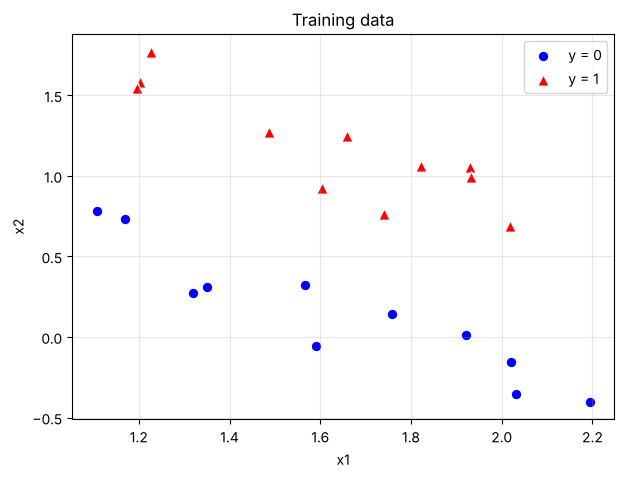

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

# Features
x1 = np.array([1.35, 2.019, 1.659, 1.566, 1.74, 1.603, 2.194, 1.202, 1.93, 1.196, 2.021,
               1.32, 1.823, 1.169, 1.226, 1.107, 2.031, 1.487, 1.921, 1.932, 1.59, 1.758])
x2 = np.array([0.311, 0.687, 1.247, 0.323, 0.765, 0.924, -0.401, 1.581, 1.052, 1.544, -0.157,
               0.272, 1.062, 0.734, 1.771, 0.78, -0.354, 1.272, 0.011, 0.994, -0.056, 0.142])
X = np.column_stack((x1, x2))

# Class
y = np.array([0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0])

# Plot the data
plt.figure(figsize=(7, 5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], marker="o", s=60, color="blue",
            edgecolors="white", linewidths=1, label="y = 0")
plt.scatter(X[y == 1, 0], X[y == 1, 1], marker="^", s=70, color="red",
            edgecolors="white", linewidths=1, label="y = 1")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Training data")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

From the plot, the two classes can be separated by a straight line: the points with y = 0 are located in the lower part of the plot (lower x2), while the points with y = 1 are located in the upper part. Therefore, **the data is linearly separable**.

Since the data is linearly separable, the optimal linear SVM is the one that separates both classes with the largest possible margin and without misclassifying any training point. This corresponds to a hard margin SVM, which can be obtained in scikit-learn by using a linear kernel with a very large regularization parameter C, so that no margin violations are allowed.

Training accuracy = 1.0000
Decision boundary: -7.4077 + 3.3159*x1 + 3.4485*x2 = 0
Margin width = 0.4181
Support vectors:
[[1.169 0.734]
 [1.921 0.011]
 [1.74  0.765]]


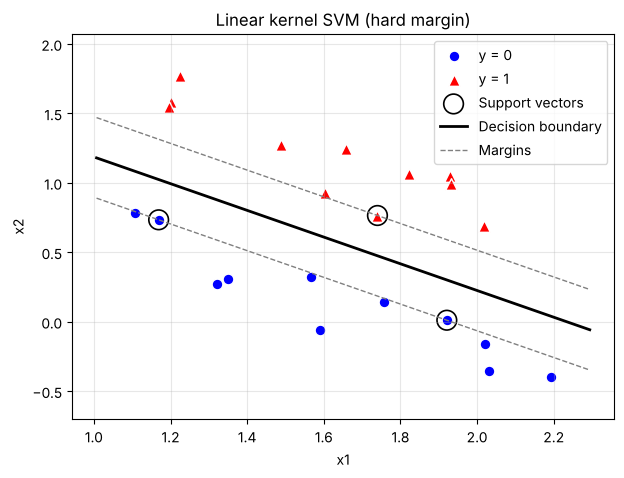

In [2]:
# Linear kernel SVM with a very large C (hard margin)
svm = SVC(kernel="linear", C=1e6)
svm.fit(X, y)

theta0 = svm.intercept_[0]
theta1, theta2 = svm.coef_[0]
margin = 2 / np.linalg.norm(svm.coef_[0])

print(f"Training accuracy = {svm.score(X, y):.4f}")
print(f"Decision boundary: {theta0:.4f} + {theta1:.4f}*x1 + {theta2:.4f}*x2 = 0")
print(f"Margin width = {margin:.4f}")
print(f"Support vectors:\n{svm.support_vectors_}")

# Plot the decision boundary and the margins
x1_line = np.linspace(X[:, 0].min() - 0.1, X[:, 0].max() + 0.1, 100)
boundary = -(theta0 + theta1 * x1_line) / theta2
margin_up = -(theta0 - 1 + theta1 * x1_line) / theta2
margin_down = -(theta0 + 1 + theta1 * x1_line) / theta2

plt.figure(figsize=(7, 5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], marker="o", s=60, color="blue",
            edgecolors="white", linewidths=1, label="y = 0")
plt.scatter(X[y == 1, 0], X[y == 1, 1], marker="^", s=70, color="red",
            edgecolors="white", linewidths=1, label="y = 1")
plt.scatter(svm.support_vectors_[:, 0], svm.support_vectors_[:, 1], s=200,
            facecolors="none", edgecolors="black", linewidths=1.2, label="Support vectors")
plt.plot(x1_line, boundary, color="black", linewidth=2, label="Decision boundary")
plt.plot(x1_line, margin_up, color="gray", linewidth=1, linestyle="--", label="Margins")
plt.plot(x1_line, margin_down, color="gray", linewidth=1, linestyle="--")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Linear kernel SVM (hard margin)")
plt.ylim(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

2.3. Compare and comment on the decision boundaries obtained from questions 2.2 and from the logistic regression model you got from the last assignment. Have you observed any decision boundary improvement? If not, what could be the reason? [2 Marks]

In [1]:
# TODO: Please provide your answers here. You can add more cells for code or texts if needed. 
# Don't delete these two comments so that it would be easier for me to locate your answers.

2.4 Add one more data point x<sub>1</sub>=1.92, x<sub>2</sub>=0.66, and y=0 to the dataset given in the question. Investigate how the regularization parameter affects the decision boundary. Summarize and comment on your results. **Note: You are allowed to use scikit-learn for this question.** [5 Marks]

In [48]:
# TODO: Please provide your answers here. You can add more cells for code or texts if needed. 
# Don't delete these two comments so that it would be easier for me to locate your answers.

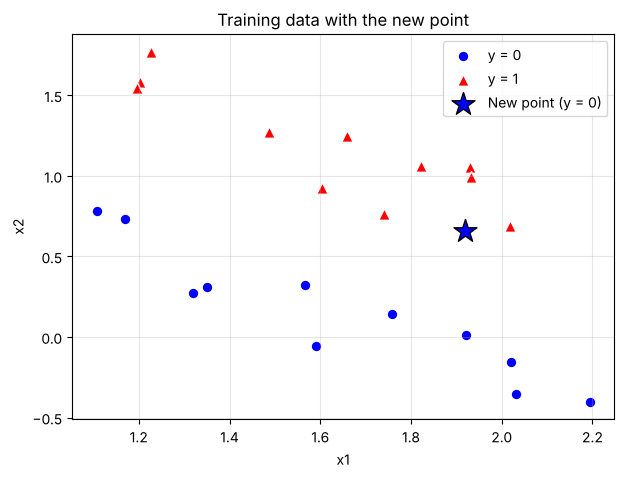

In [3]:
# Add the new data point (x1 = 1.92, x2 = 0.66, y = 0)
X_new = np.vstack((X, [1.92, 0.66]))
y_new = np.append(y, 0)

# Plot the data with the new point highlighted
plt.figure(figsize=(7, 5))
plt.scatter(X_new[y_new == 0, 0], X_new[y_new == 0, 1], marker="o", s=60, color="blue",
            edgecolors="white", linewidths=1, label="y = 0")
plt.scatter(X_new[y_new == 1, 0], X_new[y_new == 1, 1], marker="^", s=70, color="red",
            edgecolors="white", linewidths=1, label="y = 1")
plt.scatter(1.92, 0.66, marker="*", s=300, color="blue", edgecolors="black",
            linewidths=1, label="New point (y = 0)")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Training data with the new point")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

C = 0.1: accuracy = 0.8696, support vectors = 22, margin width = 2.0961
   boundary: -0.729 + 0.033*x1 + 0.954*x2 = 0
C = 1: accuracy = 0.9565, support vectors = 12, margin width = 0.8389
   boundary: -3.451 + 1.264*x1 + 2.021*x2 = 0
C = 10: accuracy = 0.9565, support vectors = 4, margin width = 0.5138
   boundary: -6.124 + 2.540*x1 + 2.950*x2 = 0
C = 100: accuracy = 0.9565, support vectors = 4, margin width = 0.2249
   boundary: -10.887 + 3.045*x1 + 8.354*x2 = 0
C = 1000: accuracy = 1.0000, support vectors = 3, margin width = 0.0527
   boundary: -44.746 + 10.219*x1 + 36.554*x2 = 0
C = 1e+06: accuracy = 1.0000, support vectors = 3, margin width = 0.0527
   boundary: -44.746 + 10.219*x1 + 36.554*x2 = 0


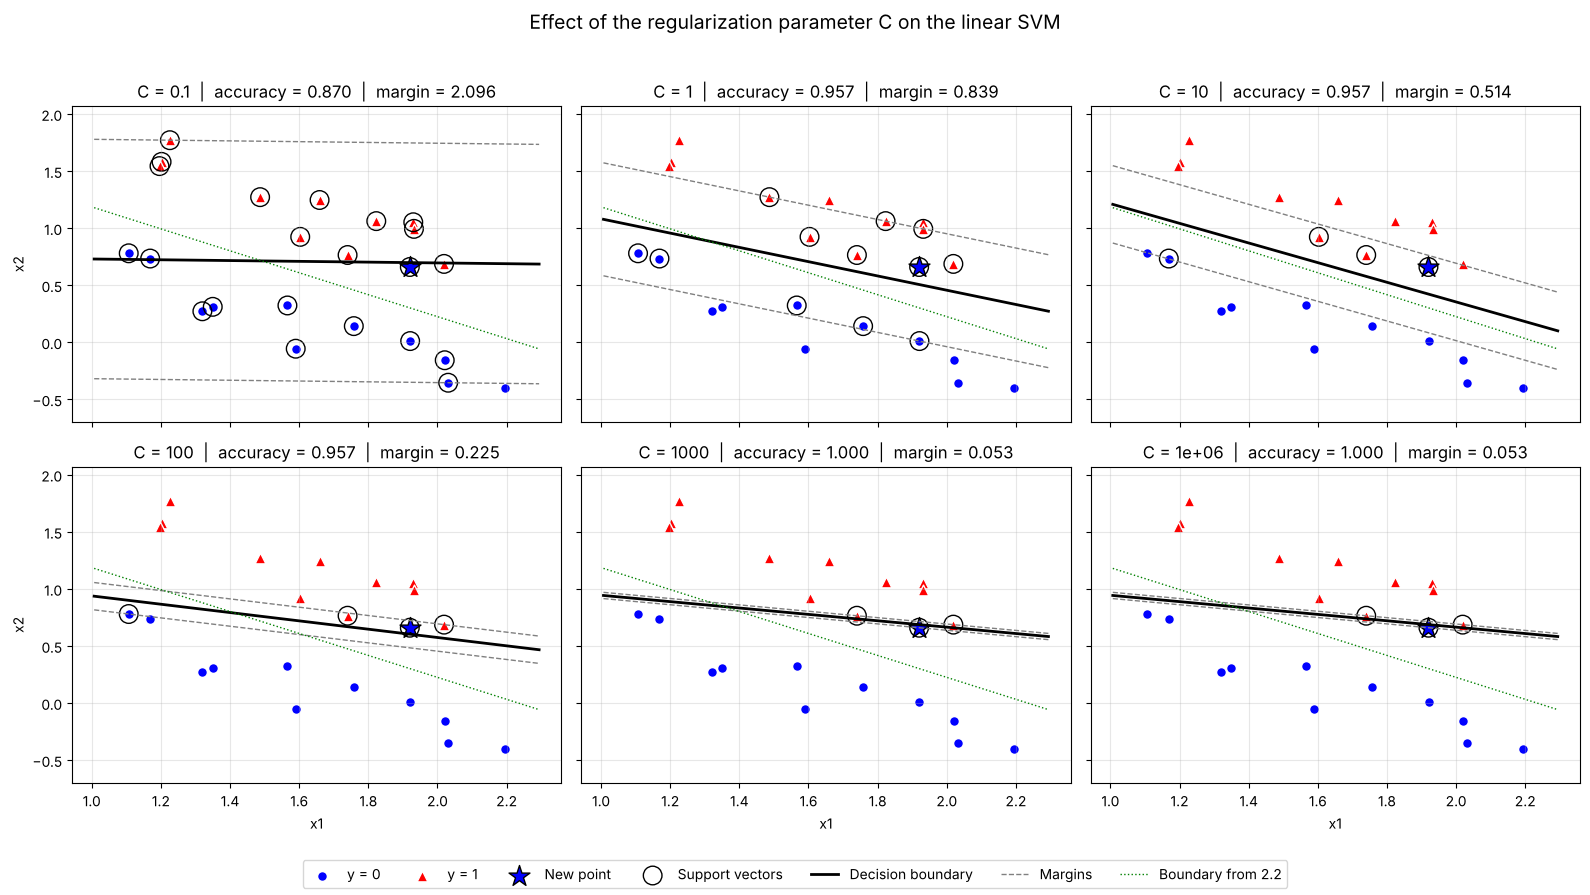

In [4]:
# Train a linear SVM for different values of the regularization parameter C
C_values = [0.1, 1, 10, 100, 1000, 1e6]
x1_line = np.linspace(X_new[:, 0].min() - 0.1, X_new[:, 0].max() + 0.1, 100)
boundary_22 = -(theta0 + theta1 * x1_line) / theta2   # boundary from question 2.2

fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, sharey=True)

for ax, C in zip(axes.flat, C_values):
    model = SVC(kernel="linear", C=C)
    model.fit(X_new, y_new)

    t0 = model.intercept_[0]
    t1, t2 = model.coef_[0]
    margin = 2 / np.linalg.norm(model.coef_[0])
    accuracy = model.score(X_new, y_new)

    print(f"C = {C:g}: accuracy = {accuracy:.4f}, support vectors = {len(model.support_)}, "
          f"margin width = {margin:.4f}\n   boundary: {t0:.3f} + {t1:.3f}*x1 + {t2:.3f}*x2 = 0")

    ax.scatter(X_new[y_new == 0, 0], X_new[y_new == 0, 1], marker="o", s=50, color="blue",
               edgecolors="white", linewidths=1, label="y = 0")
    ax.scatter(X_new[y_new == 1, 0], X_new[y_new == 1, 1], marker="^", s=60, color="red",
               edgecolors="white", linewidths=1, label="y = 1")
    ax.scatter(1.92, 0.66, marker="*", s=250, color="blue", edgecolors="black",
               linewidths=1, label="New point")
    ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=180,
               facecolors="none", edgecolors="black", linewidths=1, label="Support vectors")
    ax.plot(x1_line, -(t0 + t1 * x1_line) / t2, color="black", linewidth=2,
            label="Decision boundary")
    ax.plot(x1_line, -(t0 - 1 + t1 * x1_line) / t2, color="gray", linewidth=1,
            linestyle="--", label="Margins")
    ax.plot(x1_line, -(t0 + 1 + t1 * x1_line) / t2, color="gray", linewidth=1, linestyle="--")
    ax.plot(x1_line, boundary_22, color="green", linewidth=1, linestyle=":",
            label="Boundary from 2.2")
    ax.set_title(f"C = {C:g}  |  accuracy = {accuracy:.3f}  |  margin = {margin:.3f}")
    ax.set_ylim(X_new[:, 1].min() - 0.3, X_new[:, 1].max() + 0.3)
    ax.grid(alpha=0.3)

for ax in axes[1]:
    ax.set_xlabel("x1")
for ax in axes[:, 0]:
    ax.set_ylabel("x2")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=7)
fig.suptitle("Effect of the regularization parameter C on the linear SVM", fontsize=14)
plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.show()

**Summary and comments**

The new point (1.92, 0.66) belongs to class 0, but it is located among the class 1 points, on the wrong side of the decision boundary obtained in question 2.2 (green dotted line). It behaves like an outlier, and the way the SVM treats it depends on the regularization parameter C:

| C | Training accuracy | Support vectors | Margin width |
|---|---|---|---|
| 0.1 | 0.870 | 22 | 2.096 |
| 1 | 0.957 | 12 | 0.839 |
| 10 | 0.957 | 4 | 0.514 |
| 100 | 0.957 | 4 | 0.225 |
| 1000 | 1.000 | 3 | 0.053 |
| 1e6 | 1.000 | 3 | 0.053 |

- **Large C (1000 and above):** misclassifications are strongly penalized, so the SVM behaves like a hard margin SVM. The data is still linearly separable, so the model classifies all training points correctly, but only by rotating the boundary to an almost horizontal position and squeezing it between the new point and the class 1 points. The margin drops from 0.418 (question 2.2) to 0.053. The boundary is completely determined by a single unusual point, so the model is overfitting (high variance) and is likely to generalize poorly.
- **Intermediate C (1 to 100):** the SVM accepts misclassifying the new point in exchange for a wider margin. With C = 10, the boundary is very close to the one from question 2.2, which means the model is not significantly affected by the outlier. As C decreases from 100 to 1, the margin becomes wider and more points fall inside it, so the number of support vectors increases.
- **Small C (0.1):** the penalty for margin violations is so small that the margin becomes very wide (2.096) and all points except one fall inside it or on its edge. The boundary is almost horizontal, it nearly ignores x1, and it misclassifies 3 points. The model is too simple and is underfitting (high bias).

In conclusion, C controls the trade-off between a wide margin and few training errors: a large C gives a narrow margin and a boundary that is very sensitive to individual points (overfitting), while a small C gives a wide margin with more training errors (underfitting). For this dataset, an intermediate value (around C = 1 to 10) gives the most reasonable boundary, since it treats the new point as an outlier and keeps a boundary similar to the one obtained with the original data. In practice, the value of C should be selected using cross-validation.

---
# Quiz [10 Marks]

### Note there is only one correct answer for each question.

### TODO: Please provide your answers here:

1. B  
2. C  
3. C  
4.  
5.  
6.  
7. C  
8.  
9.  
10.  

1. Which dataset is used to fine-tune hyperparameters in a machine learning model?  
    A. Training set  
    B. Validation (dev) set  
    C. Test set  
    D. Production data
<br>

2. In K-fold cross-validation, what does 'K' represent?  
    A. Number of data points in each subset  
    B. Number of features used  
    C. Number of splits for the dataset  
    D. Number of epochs in model training  
<br>

3. Which statement about model selection is true?  
    A. Training error is the best metric for selecting a model  
    B. Test set error should be used to decide on hyperparameter values  
    C. Cross-validation accuracy is a reliable metric for model selection  
    D. Increasing model complexity always improves cross-validation accuracy  
<br>

4. You observe that adding more training data does not improve your model’s performance. What does this suggest?  
    A. The model has high variance  
    B. The model suffers from high bias  
    C. The model is optimally tuned  
    D. The training data contains too many features  
<br>

5. Which of the following statements is NOT true about SVM?

    A. It has regularization capabilities.  
    B. It handles non-linear data efficiently.  
    C. It has much improved stability.  
    D. Choosing an appropriate kernel function is easy.  
<br>

6. Which of the following statements is NOT true about SVM? 

    A. It is memory efficient.  
    B. It is versatile.  
    C. It can address a large number of predictor variables.   
    D. It doesn’t require feature scaling.  
<br>

7. What happens to the decision boundary if a support vector is removed from the training set?  
    A. The decision boundary remains unaffected  
    B. The margin between the classes may increase  
    C. The decision boundary may shift  
    D. The SVM optimization fails to converge  
<br>

8. What is a key advantage of using SVM with a soft margin in noisy datasets?  
    A. It eliminates noisy data points  
    B. It provides perfect separation between classes  
    C. It allows some data points to lie within the margin or be misclassified  
    D. It removes outliers automatically  
<br>

9. How does the Gaussian kernel measure similarity between two data points?  
    A. It computes the dot product between the two points  
    B. It measures the Euclidean distance and applies a non-linear transformation  
    C. It compares the angular distance between the points  
    D. It evaluates the sum of squared differences between the points  
<br>

10. What happens when C is set to a very large value in an SVM?  
    A. The margin becomes wider, and more points are misclassified  
    B. The model becomes less sensitive to training data  
    C. The margin becomes smaller, with fewer misclassifications allowed  
    D. The model behaves like logistic regression  
<br>